# Notebook 1 - Resumindo dados de uma Base de Marketing (Análise Univariada)

# Objetivos

1. Analisar a base proposta e resumir os dados utilizando **medidas estatísticas e gráficos** para identificar padrões no comportamento de compra e nível de satisfação;
2. Implementar Gráficos com a biblioteca Seaborn;


In [24]:
# Imports
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
import math

# adiciona diretório raiz do projeto ao sys.path
sys.path.insert(0, str(Path.cwd().parent))

# configurações gerais
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid', palette='pastel')
%matplotlib inline

# 1. Carga dos Dados

In [2]:
data_path = Path.cwd().parent / 'data' / 'resumir-dados-marketing.xlsx'

raw_data = pd.read_excel(
    data_path,
    engine='openpyxl',
    sheet_name='Dados'
)

print(f"Dataset carregado de: {data_path}")
print("\n========= Dimensões do Dataset =========\n")
print(f"Número de Linhas: {raw_data.shape[0]}")
print(f"Número de Colunas: {raw_data.shape[1]}")
raw_data.head()

Dataset carregado de: c:\Users\jooar\ds\LABS\data-analisys-labs\data-analisys-labs\projects\resumindo-dados-marketing\data\resumir-dados-marketing.xlsx

========= Dimensões do Dataset =========

Número de Linhas: 100
Número de Colunas: 8


,id_cliente,idade,renda_mensal,valor_total_compras,frequencia_compras,tempo_cliente,avaliacao_satisfacao,tempo_navegacao
0,C_001,56,4583.30,2367.68,17,35,4,28.45
1,C_002,46,2071.79,2096.84,29,50,8,30.81
2,C_003,32,12601.00,9154.57,13,25,5,14.06
3,C_004,60,11189.15,12813.50,8,24,2,12.74
4,C_005,25,11477.09,7739.77,7,13,6,17.59


## 1.1 Visão Geral dos Dados
**Descrição**: Os dados representam registros de compras de 100 clientes, considerando uma linha para cada cliente único.

| Variável | Descrição |
|---|---|
| **id_cliente** | Identificador único do cliente |
| **idade** | Idade do cliente |
| **renda_mensal** | Renda mensal do cliente (em R$) |
| **valor_total_compras** | Valor total gasto pelo cliente nos últimos 12 meses (em R$) |
| **frequência_compras** | Quantidade de compras feitas no último ano |
| **tempo_cliente** | Tempo desde a primeira compra (em meses) |
| **avaliacao_satisfacao** | Nota de satisfação do cliente (1 a 10) |
| **tempo_navegacao** | Tempo médio de navegação no site antes da compra (em minutos) |


Antes de seguirmos com as análises é importante fazer uma verificação na qualidade dos dados (**Sanity Check**), vamos verificar:
- a presença de dados duplicados;
- verificar se há dados nulos ou inválidos;
- a presença de outliers.



In [3]:
# informações gerais sobre o dataset
print("========= Informações do Dataset =========\n")
raw_data.info()

print("\n========= Dados Duplicados =========")
dados_duplicados = raw_data.duplicated().sum()
print(f"Número de linhas duplicadas: {dados_duplicados}")

========= Informações do Dataset =========

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_cliente            100 non-null    str    
 1   idade                 100 non-null    int64  
 2   renda_mensal          100 non-null    float64
 3   valor_total_compras   100 non-null    float64
 4   frequencia_compras    100 non-null    int64  
 5   tempo_cliente         100 non-null    int64  
 6   avaliacao_satisfacao  100 non-null    int64  
 7   tempo_navegacao       100 non-null    float64
dtypes: float64(3), int64(4), str(1)
memory usage: 6.4 KB

========= Dados Duplicados =========
Número de linhas duplicadas: 0


**Não foram identificados valores nulos ou duplicados na base**. Seguindo na investigação, será verificado se há valores inválidos e outliers na base.

In [4]:
#dropando a variável id_cliente, pois não é relevante para a análise
df = raw_data.drop(columns=['id_cliente'])

num_vars = [col for col in df.columns if df[col].dtype in ['float64', 'int64']]

print("\n=========== Percentual de Outliers nas Variáveis Numéricas ===========\n")
for var in num_vars:
    Q1 = df[var].quantile(0.25)
    Q3 = df[var].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[var] < lower_bound) | (df[var] > upper_bound)]
    outlier_percentage = (len(outliers) / len(df)) * 100
    print(f"{var}: {outlier_percentage:.2f}% de outliers")


=========== Percentual de Outliers nas Variáveis Numéricas ===========

idade: 0.00% de outliers
renda_mensal: 0.00% de outliers
valor_total_compras: 0.00% de outliers
frequencia_compras: 0.00% de outliers
tempo_cliente: 0.00% de outliers
avaliacao_satisfacao: 0.00% de outliers
tempo_navegacao: 0.00% de outliers


Após a verificação, **não foram identificados outliers**. Não há variáveis qualitativas na base, apenas quantitativas.

A classificação das variáveis é a seguinte:
- **Quantitativa Discreta**: `idade`, `frequencia_compras`, `tempo_cliente` e `avaliacao_satisfacao`
- **Quantitativa Contínua**: `renda_mensal`, `valor_total_compras` e `tempo_navegacao`

# 2. Estatística Descritiva

### Medidas Resumo

A **Estatística Descritiva** é uma frente da estatística que envolve um conjunto de técnicas utilizadas para descrever e resumir um conjunto de dados. Entre essa técnicas, as mais utilizadas para **resumir valores numéricos** são as **Medidas Resumo**. Elas podem ser agrupadas em alguns grupos, os mais comuns são:
1. **Medidas de Posição**: indicam a posição em relação a amostra analisada (*Ex.: Média, Mediana, Mínimos e Máximos, Quartis e Percentis*);
2. **Medidas de Dispersão**: indicam a variabilidade (*Ex.: Amplitude, Desvio Padrão e Variância*).

> É preciso tomar cuidado ao utilizar essas estatísticas para resumir os dados afim de evitar análises equivocadas. De modo geral, **nunca utilizamos uma única estatística para resumir os dados**. Para se obter uma boa análise, utiliza-se várias estatísticas em combinação para identificar o perfil da posição e dispersão da variável de interesse.

Em Python, temos uma forma muito simples e prática para calcular as estatísticas descritivas mais comuns para as variáveis numéricas. Podemos utilizar o método `.describe()` no *DataFrame* que contém as variáveis numéricas que queremos analisar para obtermos uma tabela contendo as principais estatísticas descritivas.

> O método retorna a contagem, média, desvio padrão (std), mínimo, máximo e os quartis. É um método muito útil para resumir inicialmente as variáveis numéricas do dataset. Também é possível utilizar esse método para variáveis categóricas, ao invés de apresentar a média ele calcula a moda.


In [5]:
print("\n=========== Estatísticas Descritivas das Variáveis Numéricas ===========\n")
display(df[num_vars].describe().round(2))


=========== Estatísticas Descritivas das Variáveis Numéricas ===========



,idade,renda_mensal,valor_total_compras,frequencia_compras,tempo_cliente,avaliacao_satisfacao,tempo_navegacao
count,100.00,100.00,100.00,100.00,100.00,100.00,100.00
mean,40.92,8208.55,8359.67,17.44,32.21,5.80,17.77
std,14.05,3749.67,4480.66,11.42,17.92,2.95,6.92
min,18.00,2071.79,1982.91,1.00,1.00,1.00,-0.70
25%,30.50,5108.05,4566.72,8.00,16.75,3.00,12.48
50%,41.00,8391.12,7594.19,17.00,32.50,6.00,18.14
75%,53.25,11479.04,11284.27,28.25,49.25,8.25,23.60
max,65.00,14813.46,20903.67,42.00,58.00,10.00,30.81


### Tabelas de Frequência

As **tabelas de frequência** são uma técnica muito comum para resumir **variáveis qualitativas**. Ela consegue contar a quantidade de vezes que o valor de uma variável categórica ocorro em um conjunto de dados (frequência absoluta). Também é possível apresentar esses dados em termos relativos (percentuais) e acumulativos.

A *Análise de Pareto* é um conceito muito utilizado para representar a concentração do conjunto de dados. Ele é calculado a partir da soma das frequências relativas em uma base ordenada.

> É possível utilizar a tabela de frequência para os dados quantitativas, porém é necessário agrupar em faixas de valores para facilitar o agrupamento (processo conhecido como discretização). Como a nossa base não contém uma variável qualitativa para a demonstração, vou utilizar a variável `idade` para exemplificar a construção da tabela de frequência e já demonstrar como funciona o processo de discretização.

Em Python, para criar as tabelas de frequência normalmente utilizamos o `.crosstab()` para trazer a frequência absoluta e depois calculamos manualmente as frequências relativas e acumuladas.

In [8]:
# Discretização da variável idade em faixas etárias
df["faixa_etaria"] = pd.cut(
    df["idade"],
    bins=[17, 27, 36, 46, 55, 65],
    labels=["18 a 27", "28 a 36", "37 a 46", "47 a 55", "56 a 65"]
)

In [22]:
# Frequência absoluta
tabela_frequencias = pd.crosstab(
    index=df["faixa_etaria"],
    columns="frequencia_absoluta"
)

# Frequência relativa
tabela_frequencias["frequencia_relativa (%)"] = (
    tabela_frequencias["frequencia_absoluta"]
    / tabela_frequencias["frequencia_absoluta"].sum()
).mul(100).round(2)

# Frequência acumulada
tabela_frequencias["frequencia_acumulada (%)"] = (
    tabela_frequencias["frequencia_absoluta"].cumsum()
)

tabela_frequencias = tabela_frequencias.reset_index()
tabela_frequencias.columns.name = None
tabela_frequencias.index.name = "faixa_etaria"

display(
    tabela_frequencias.style
    .hide(axis="index")
    .format({
        "frequencia_relativa (%)": "{:.2f}%", 
        "frequencia_acumulada (%)": "{:.2f}%"
    })
)

faixa_etaria,frequencia_absoluta,frequencia_relativa (%),frequencia_acumulada (%)
18 a 27,22,22.00%,22.00%
28 a 36,18,18.00%,40.00%
37 a 46,27,27.00%,67.00%
47 a 55,10,10.00%,77.00%
56 a 65,23,23.00%,100.00%


# 3. Visualização Gráfica

Usar gráficos facilita ainda mais a interpretação do comportamento desses dados. Assim como na estatística descritiva, a visualização gráfica depende do tipo de variável que queremos representar. Para cada tipo de variável e análise, temos um tipo específico de gráfico para utilizar.

> Para as análises univariadas abordadas neste notebook, vamos utilizar dois gráficos: **Histogramas** e **Boxplots**.

### Histogramas

Os **Histogramas** são gráficos utilizados para resumir variáveis quantitativas. Em um histograma, a área da barra equivale a frequência relativa da faixa de valor que ela representa. Ele é muito utilizado para verificar a distribuição das frequências em uma determinada variável.



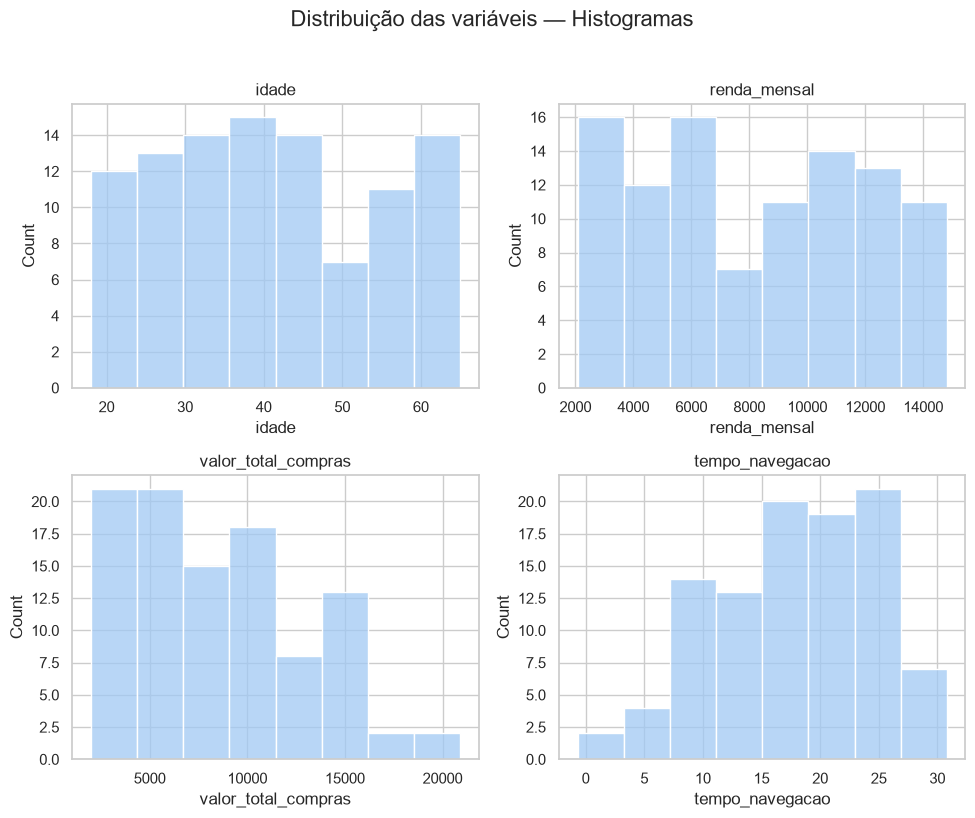

In [31]:
use_cols = ['idade', 'renda_mensal', 'valor_total_compras', 'tempo_navegacao']

n_cols = 2
n_rows = math.ceil(len(use_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(5 * n_cols, 4 * n_rows),
    squeeze=False
)

for ax, coluna in zip(axes.flat, use_cols):
    sns.histplot(data=df, x=coluna, ax=ax)
    ax.set_title(coluna)

# Remove os eixos que sobraram quando a quantidade de variáveis não é múltipla de n_cols
for ax in axes.flat[len(use_cols):]:
    ax.remove()

# título geral do gráfico
fig.suptitle("Distribuição das variáveis — Histogramas", fontsize=16, y=1.02)

plt.tight_layout()
plt.show()

### Boxplots

Os **Boxplots** são perfeitos para resumir as medidas de posição e dispersão dos dados de uma maneira muito prática.

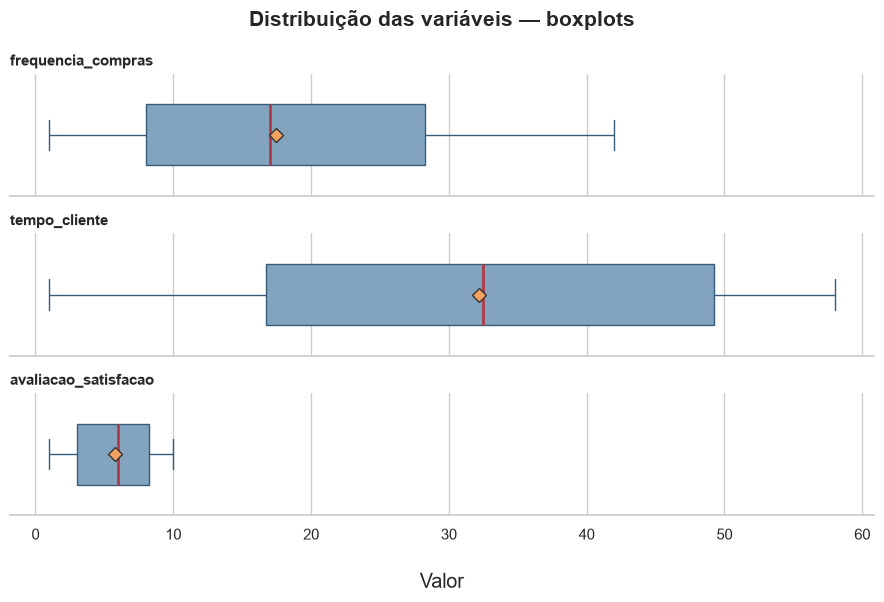

In [39]:
use_cols = ['frequencia_compras', 'tempo_cliente', 'avaliacao_satisfacao']

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(
    nrows=len(use_cols),
    ncols=1,
    figsize=(9, max(2.5, 2 * len(use_cols))),
    sharex=True,
    squeeze=False
)

for ax, coluna in zip(axes[:, 0], use_cols):
    sns.boxplot(
        data=df,
        x=coluna,
        ax=ax,
        color="#78A6C8",
        width=0.5,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "#F4A261",
            "markeredgecolor": "#333333",
            "markersize": 7,
        },
        fliersize=3,
        medianprops={"color": "#B23A48", "linewidth": 2},
        boxprops={"edgecolor": "#355C7D"},
        whiskerprops={"color": "#355C7D"},
        capprops={"color": "#355C7D"},
        flierprops={
            "marker": "o",
            "markerfacecolor": "#B23A48",
            "markeredgecolor": "none",
            "alpha": 0.5,
        },
    )
    ax.set_title(coluna, loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
    sns.despine(ax=ax, left=True)

fig.suptitle("Distribuição das variáveis — boxplots", fontsize=15, fontweight="bold")
fig.supxlabel("Valor")
fig.tight_layout()
plt.show()

# 4. Observações Importantes

- **Qualidade da base:** são 100 clientes, sem valores nulos ou linhas duplicadas. O critério do intervalo interquartil (IQR) não identificou outliers nas variáveis numéricas.
- **Idade:** os clientes têm de 18 a 65 anos; a média é 40,92 e a mediana, 41. A faixa de 37 a 46 anos reúne a maior parcela (27%), enquanto 47 a 55 anos reúne a menor (10%).
- **Renda mensal:** varia de R$ 2.071,79 a R$ 14.813,46, com média de R$ 8.208,55 e mediana de R$ 8.391,12. A proximidade entre média e mediana indica que os valores centrais são semelhantes, embora haja ampla variação entre clientes.
- **Valor total de compras:** varia de R$ 1.982,91 a R$ 20.903,67. A média (R$ 8.359,67) supera a mediana (R$ 7.594,19), e o histograma mostra uma cauda à direita: compras de maior valor são menos frequentes.
- **Frequência de compras:** a frequência tem média de 17,44 compras, mediana de 17 e amplitude de 1 a 42 compras. 
- **Tempo como cliente:** O tempo como cliente tem mediana de 32,5 meses e varia de 1 a 58 meses.
- **Satisfação:** a média é 5,8 e a mediana, 6, em uma escala de 1 a 10. As notas cobrem toda a escala, indicando percepções variadas entre os clientes.
- **Tempo de navegação:** a média é 17,77 minutos e a mediana, 18,14, mas o mínimo registrado é -0,70 minuto. Esse valor é incompatível com a duração de uma navegação e precisa ser conferido na fonte, mesmo sem ter sido sinalizado como outlier pelo IQR.

# 5. Considerações Finais

Nesta notebook, foi explorado as **estatísticas descritivas** para resumir a posição e a dispersão das variáveis. A tabela de frequências complementou essa leitura ao mostrar a distribuição dos clientes por faixa etária.

Os **histogramas e boxplots** ajudaram a visualizar o formato e a variabilidade das distribuições. Em conjunto, eles evidenciaram a cauda à direita nos valores totais de compras, a dispersão na frequência de compras e no tempo de relacionamento e **notas de satisfação concentradas em torno de 6**, numa escala de 1 a 10.

A exploração não encontrou valores ausentes, duplicações ou outliers pelo critério IQR; ainda assim, **o mínimo de -0,70 minuto em tempo de navegação** deve ser validado antes de interpretar essa variável. Como a análise é univariada, os resultados descrevem a amostra e não estabelecem relações de causa e efeito. Eles servem de base para a análise bivariada a seguir.


Veja o [notebook 2 - analise bivariada](notebooks\analise-bivariada.ipynb)